In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = 'retina'
import astropy.units as u
import astropy.constants as c
from scipy.signal.windows import blackmanharris
from scipy.signal import medfilt
from scipy.signal import welch
from rich.progress import track
from scipy.spatial.distance import pdist

In [2]:
# Define key interferometer parameters
central_freq = 100*u.MHz
nbins = 2**15
samp_rate = 16e6
dt = 1/samp_rate

# Antenna Config #

Array comprised of 9 antennas with diameter = 5.00 m


(np.float64(-1.467682018871869),
 np.float64(1.467682018871869),
 np.float64(-1.467682018871869),
 np.float64(1.467682018871869))

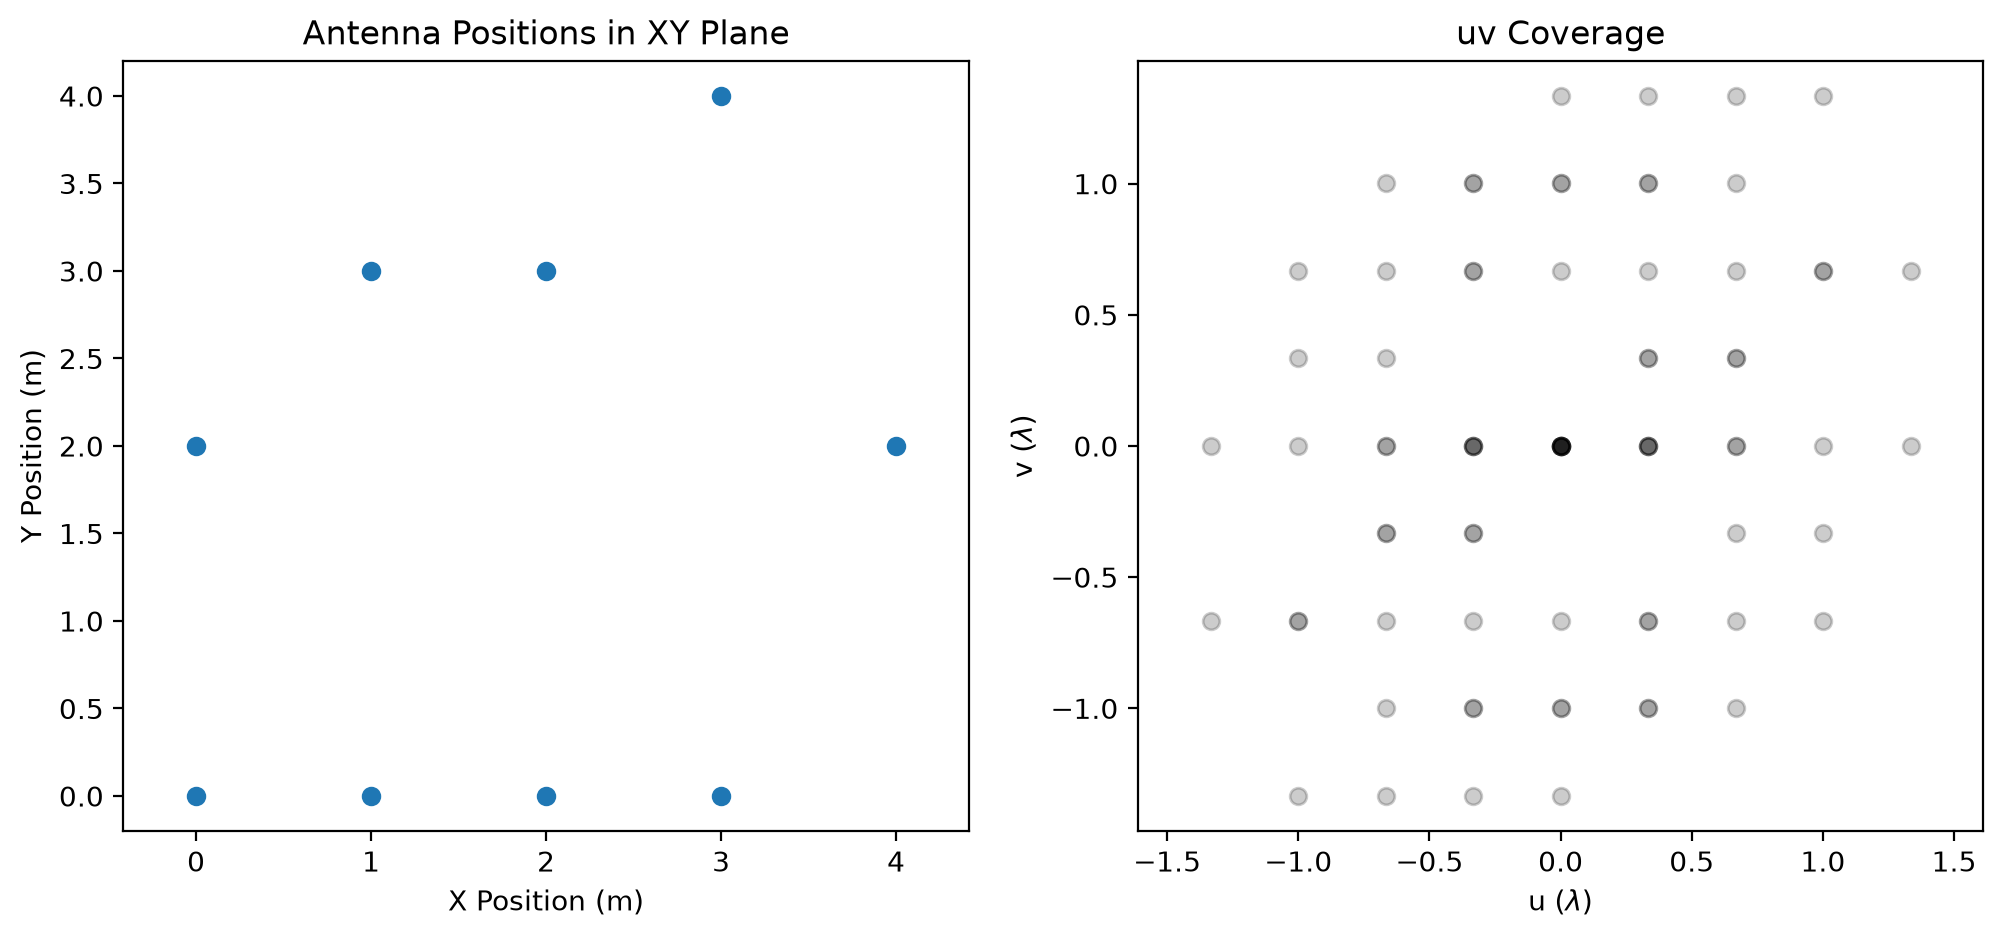

In [3]:
# define antenna positions in local coordinates (x, y, z) in meters
posx = [0, 1, 2, 3, 4, 0, 1, 2, 3]
posy = [0, 0, 0, 0, 2, 2, 3, 3, 4]
posz = [0, 0, 0, 0, 0, 0, 0, 0, 0]

# generate artificial random antennas (optional - for testing)
simulate_antennas = False # toggle random antennas generation here
if simulate_antennas:
    for i in range(7):
        posx.append(random.uniform(-5, 5))
        posy.append(random.uniform(-5, 5))
        posz.append(random.uniform(-5, 5))

# assemble position array and derive important properties
pos = np.array([posx, posy, posz]).T*u.m
num_antennas = pos.shape[0]
diameter = np.max(pdist(pos)) * u.m
print(f"Array comprised of {num_antennas} antennas with diameter = {diameter:.2f}")

# plot antenna configuration in local coordinates
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(pos[:, 0], pos[:, 1])
ax[0].set_xlabel('X Position (m)')
ax[0].set_ylabel('Y Position (m)')
ax[0].set_title('Antenna Positions in XY Plane')
ax[0].axis('equal')

# compute uv coordinate array and plot uv coverage
def compute_uv_coordinates(ant_pos, dtype=np.float32):
    num_ant = len(ant_pos)
    u_ant = ant_pos[:,0]
    v_ant = ant_pos[:,1]
    result = np.zeros((num_ant, num_ant, 2), dtype=dtype)*u.m
    for ant1 in range(num_ant):
        for ant2 in range(num_ant):
            result[ant1, ant2, 0] = u_ant[ant2] - u_ant[ant1]
            result[ant1, ant2, 1] = v_ant[ant2] - v_ant[ant1]
    return result

uv = compute_uv_coordinates(pos)
uvwl = (uv*central_freq/c.c).decompose()

ax[1].scatter(uvwl[:,:,0], uvwl[:,:,1], c='black', alpha=0.2)
ax[1].set_xlabel(r'u ($\lambda$)')
ax[1].set_ylabel(r'v ($\lambda$)')
ax[1].set_title('uv Coverage')
ax[1].axis('equal')

### Load the data
truncinate the data in nbins

In [4]:
# read in raw data
fp = '/data2/hoppener/radio-astronomy-by-notebooks/test_data/'
raw_data = [np.fromfile(f"{fp}init_data_{ant+1}", dtype=np.complex64) for ant in track(range(2), description="Loading data")]

# truncate data to same length (compatible with nbins) for all antennas
minlen = min(len(data) for data in raw_data)
nblocks = int((minlen // 10) // nbins)  # divide minlen to reduce data size even further for saving resources during testing
trunc = int(nblocks * nbins)
raw_data = [data[:trunc] for data in raw_data]
print(f"Data for {len(raw_data)} antennas extracted.")
print(f"{trunc} data points from each antenna.")

Output()

Data for 2 antennas extracted.
16121856 data points from each antenna.


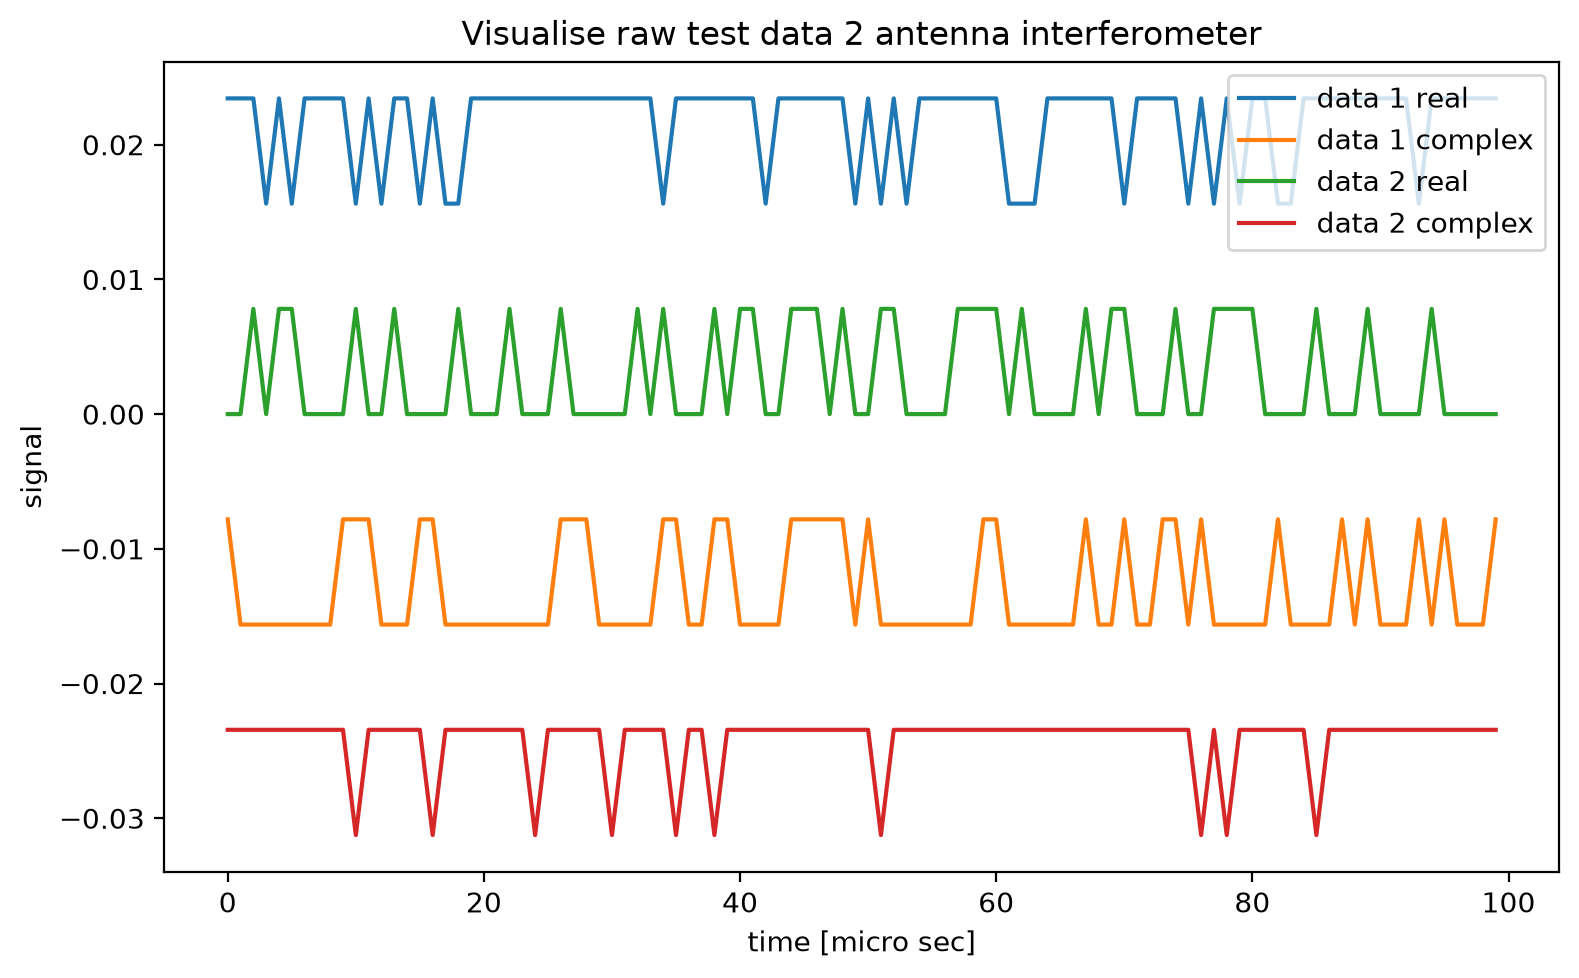

In [5]:
# visualise cut out of raw data
fig, ax = plt.subplots(figsize=(8, 5))
ax.set_title('Visualise raw test data 2 antenna interferometer')
ax.plot(np.real(raw_data[0][0:100]), label = 'data 1 real')
ax.plot(np.imag(raw_data[0][0:100]), label = 'data 1 complex')
ax.plot(np.real(raw_data[1][0:100]), label = 'data 2 real')
ax.plot(np.imag(raw_data[1][0:100]), label = 'data 2 complex')
ax.set_xlabel("time [micro sec]")
ax.set_ylabel('signal')
ax.legend()
fig.tight_layout()
plt.show()

### Calculate FFT of the 2 antenna's

Output()

/data2/hoppener/PythonRA311/lib/python3.11/site-packages/matplotlib/cbook.py:1810: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/data2/hoppener/PythonRA311/lib/python3.11/site-packages/matplotlib/cbook.py:1407: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)


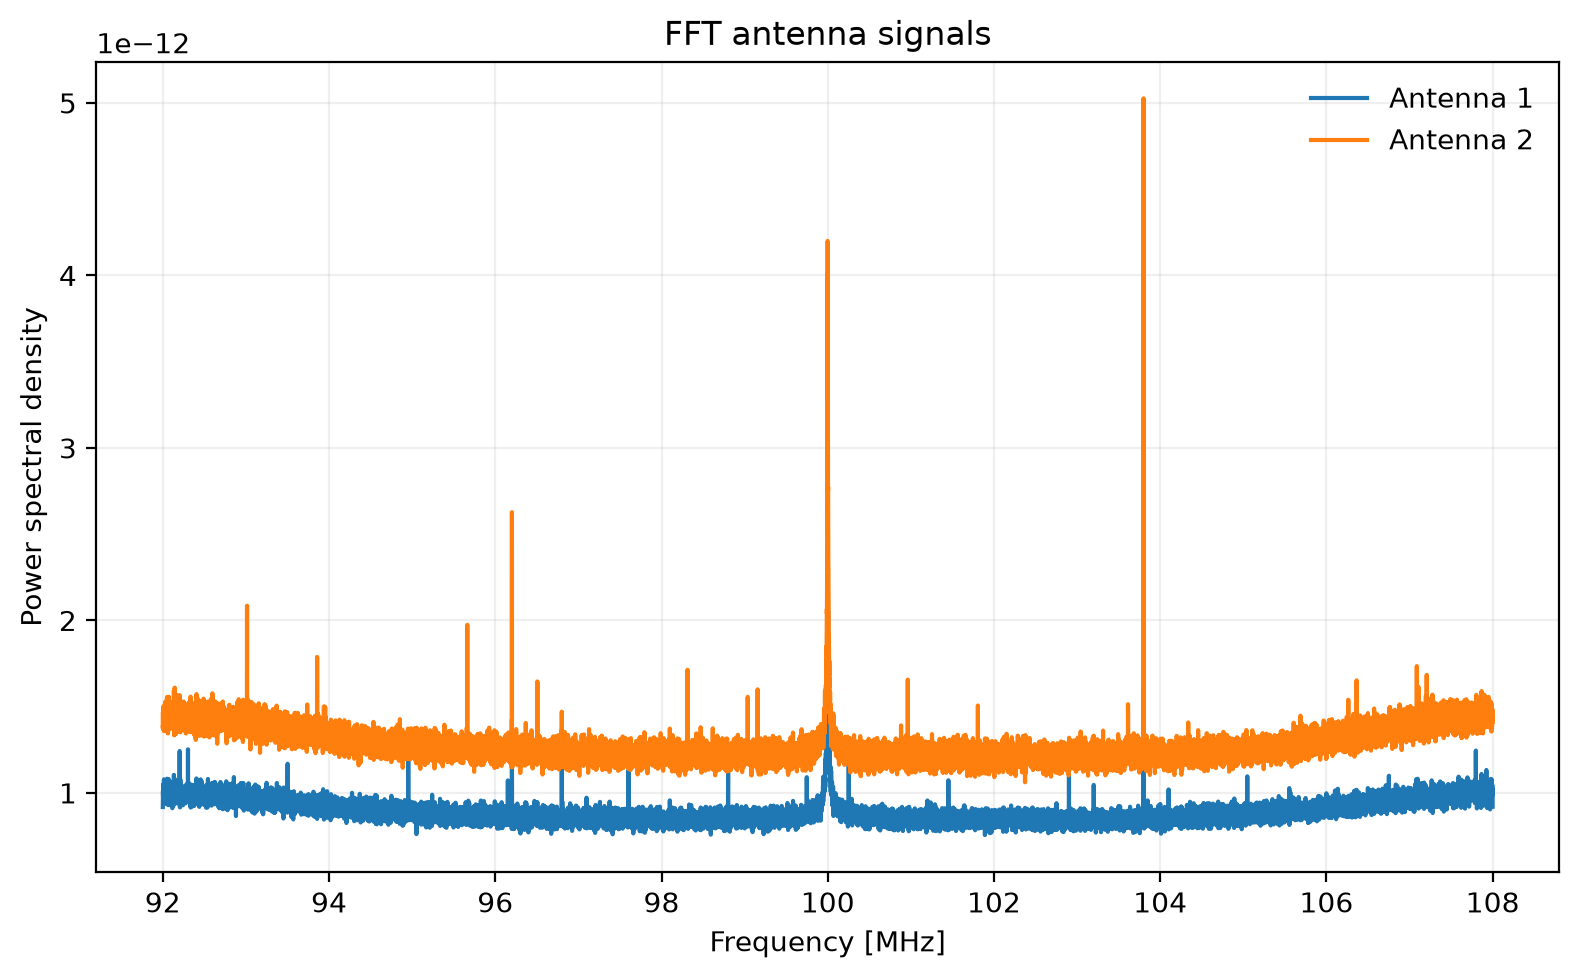

In [6]:
# Generate ACM
acm = np.zeros((num_antennas, num_antennas), dtype='complex64')
subband = (nbins // 2) + 430 # look at subband 430
window = blackmanharris(nbins)
freq = np.zeros(len(raw_data))
fft_data = np.zeros((num_antennas, nbins), dtype='complex64')

# Calculate FFTs
for i in track(range(2), description="Computing FFTs"):
    df = raw_data[i]
    df = df - np.mean(df) # Remove offset
    frequency, fft_output = welch(df, fs=samp_rate, window=window, nperseg=nbins)
    freq = np.fft.fftshift(frequency) + central_freq.to(u.Hz).value
    fft_data[i] = np.fft.fftshift(fft_output)

# Plot FFT
fig, ax = plt.subplots(figsize=(8, 5))
ax.set_title('FFT antenna signals')
ax.plot(freq / 1e6, fft_data[0], label='Antenna 1')
ax.plot(freq / 1e6, fft_data[1], label='Antenna 2')
ax.set_xlabel('Frequency [MHz]')
ax.set_ylabel('Power spectral density')
ax.grid(alpha=0.2)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()


### plot the shifted cross correlated spectra to check for time delays

/var/tmp/hoppener/ipykernel_116197/2843169427.py:17: ComplexWarning: Casting complex values to real discards the imaginary part
  correlations[i] = np.sum(cross_spectrum)


Maximum correlation: 3.7647975282311723e-20
Time delay: 0.0 seconds
Sample shift: 50


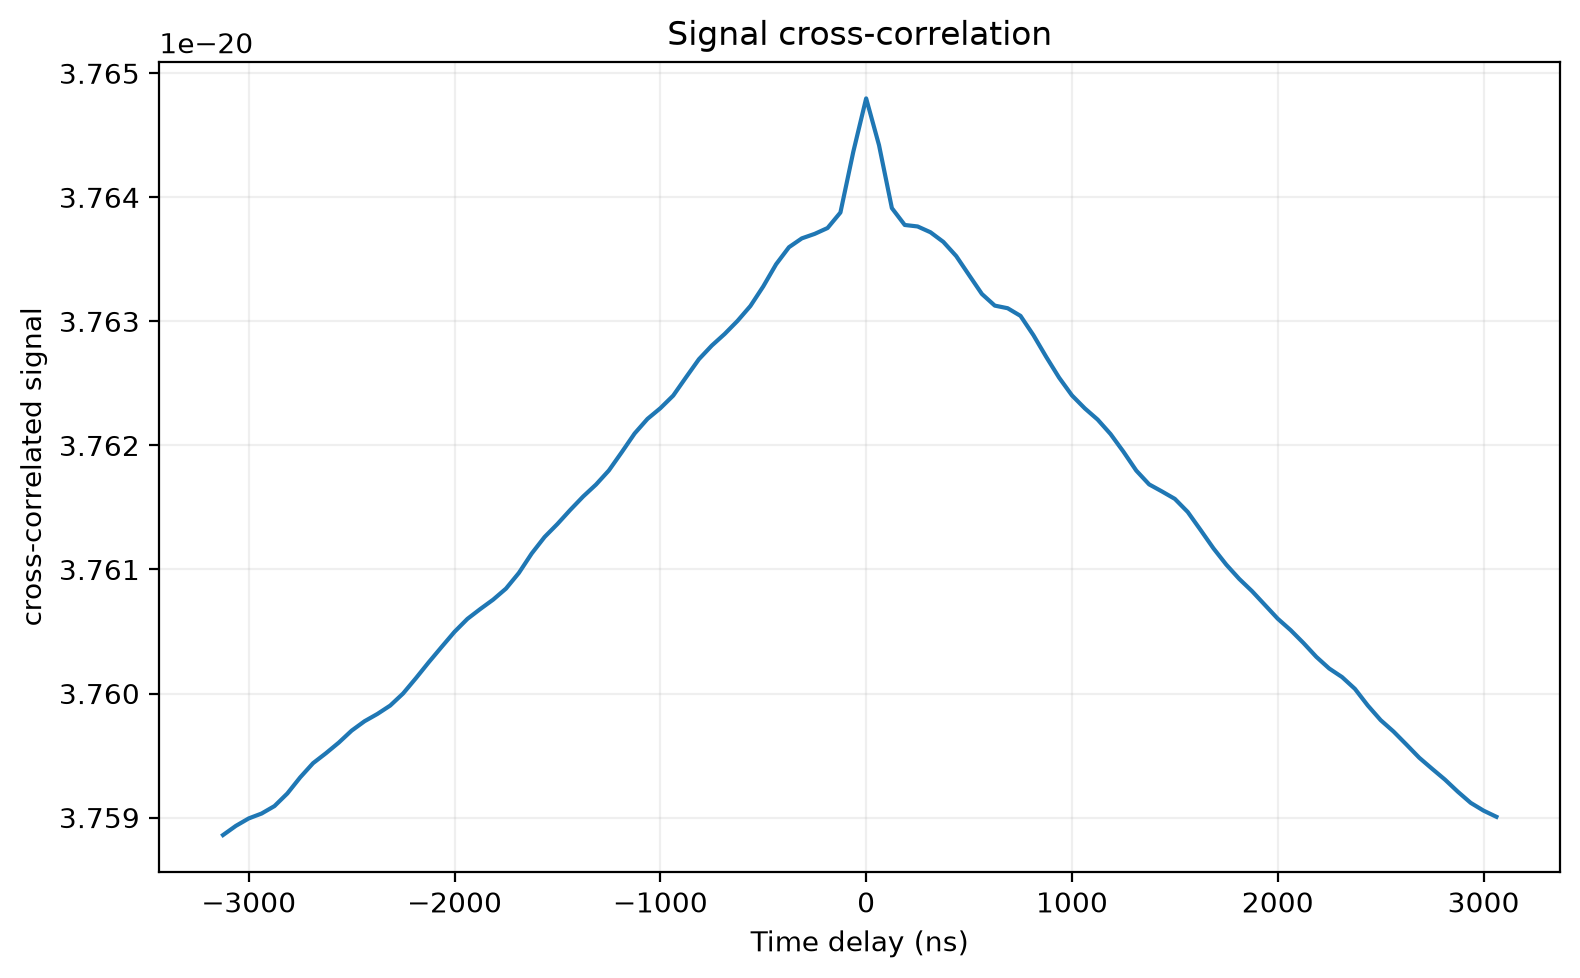

In [7]:
# correlate the signal
n_shifts = 100

correlations = np.zeros(n_shifts)
time_delays = np.zeros(n_shifts)

for i in range(n_shifts):
    antenna2 = fft_data[1]
    
    # Shift antenna 2 from -50 to +50 datapoints
    shifted_a2 = np.roll(antenna2, i-50)

    # cross correlate the two spectra
    cross_spectrum = fft_data[0] * np.conj(shifted_a2)
    
    # Calculate correlation coefficient
    correlations[i] = np.sum(cross_spectrum)

    # Convert sample shift to time delay (dt per data point)
    time_delays[i] = i * dt - (50*dt)

# Find maximum correlation
max_index = np.argmax(np.abs(correlations))

print('Maximum correlation:', correlations[max_index])
print('Time delay:', time_delays[max_index], 'seconds')
print('Sample shift:', max_index)

# visualise time delayed cross correlation
fig, ax = plt.subplots(figsize=(8, 5))
ax.set_title('Signal cross-correlation')
ax.plot(time_delays * 1e9, correlations)
ax.set_xlabel('Time delay (ns)')
ax.set_ylabel('cross-correlated signal')
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

### Comute ACM cube
add the subband visibilities to a data cube

In [8]:
# Generate articifial phase shifted data for imaginary antennas
s = np.array([0.15, 0.1, np.sqrt(1- 0.15**2 - 0.1**2) - 1]) # pointing direction arrival radio wave
for i in range(2, num_antennas):
    b = pos[i]
    tau = (np.dot(b, s)/c.c).value # geometric time delay at antenna position
    phase_shift = np.exp(-2j * np.pi * freq * tau)
    fft_data[i] = fft_data[0] * phase_shift

for ant1 in track(range(num_antennas), description="Assembling ACM"):
    for ant2 in range(num_antennas):
        # calculate the cross correlated spectra
        cross_corr = fft_data[ant1] * np.conj(fft_data[ant2])
        
        # the visibility is the cross correlation of each subband
        acm[ant1, ant2] = cross_corr[subband]
print("ACM generated succesfully!")

Output()

ACM generated succesfully!


### Create image of ACM cube

In [13]:
# Helper functions for generating images
def pixel_brightness(acm_single_pol, l, m, uv, frequency):
    a = acm_single_pol.astype(np.complex64)
    n = a.shape[0]
    uv_l = uv.to(u.m).astype(np.float32)
    uv_l = (uv_l * frequency/c.c).decompose()
    ll = l.to(u.rad).value
    mm = m.to(u.rad).value
    mask = np.ones((n, n), dtype=np.float32)
    mask -= np.diag(np.ones(n, dtype=np.float32)) # remove auto-correlations
    num_vis = mask.sum()
    brightness = (a*mask*np.exp(2j*np.pi*(uv_l[...,0]*ll + uv_l[...,1]*mm))).real.sum()
    return brightness/num_vis

def subband_frequency(subband_number, clock_frequency=20*u.MHz):
    return (subband_number/nbins)*clock_frequency + (central_freq - clock_frequency/2)

def make_image(acm, num_pix, uv, frequency, l_range=(1.0, -1.0), m_range=(-1.0, 1.0)):
    img = np.zeros((num_pix, num_pix), dtype=np.float32)
    l_coor = np.linspace(*l_range, num_pix)*u.rad
    m_coor = np.linspace(*m_range, num_pix)*u.rad

    for m_ix, m in enumerate(track(m_coor, description="Generating image")):
        for l_ix, l in enumerate(l_coor):
            img[m_ix, l_ix] = pixel_brightness(acm, l, m, uv, frequency)
    pixel_sep = m_coor[1]-m_coor[0]
    half = pixel_sep.to(u.rad).value/2.0
    img_extent =(l_coor[0].to(u.rad).value-half, m_coor[0].to(u.rad).value+half, 
                 l_coor[-1].to(u.rad).value+half, m_coor[-1].to(u.rad).value-half)    
    return img, img_extent

Output()

Number of pixels should be 8


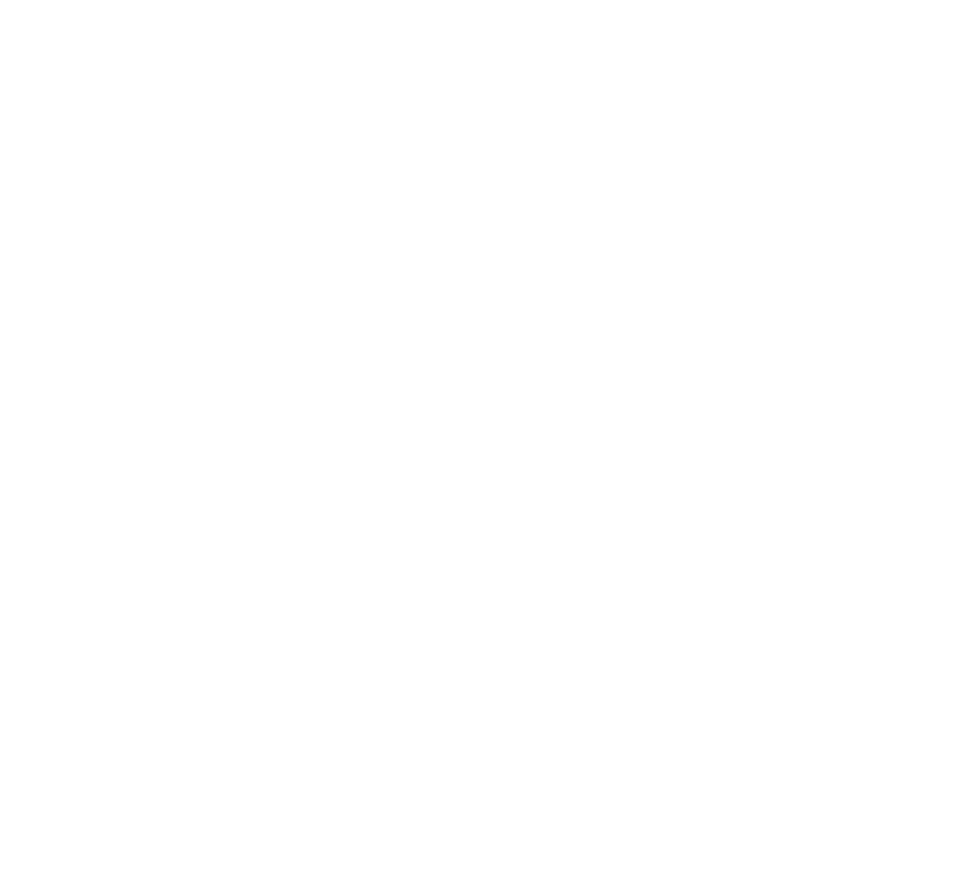

In [18]:
# Make and plot image
f = subband_frequency(subband)
fwhm =  ((c.c/f)/(diameter)).decompose()*u.rad
num_pix = int(2*u.rad / (fwhm/2.5))
print(f"Number of pixels should be {num_pix}")

img, extent = make_image(acm, num_pix, uv, f)

# Plot image
fig, ax = plt.subplots(figsize=(5, 5))

im = ax.imshow(np.abs(img), origin='lower', extent=extent)

ax.set_title(f"Simulated image at {f.to(u.MHz):.3f}")
ax.set_xlabel("pixel x")
ax.set_ylabel("pixel y")

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.show()


Output()

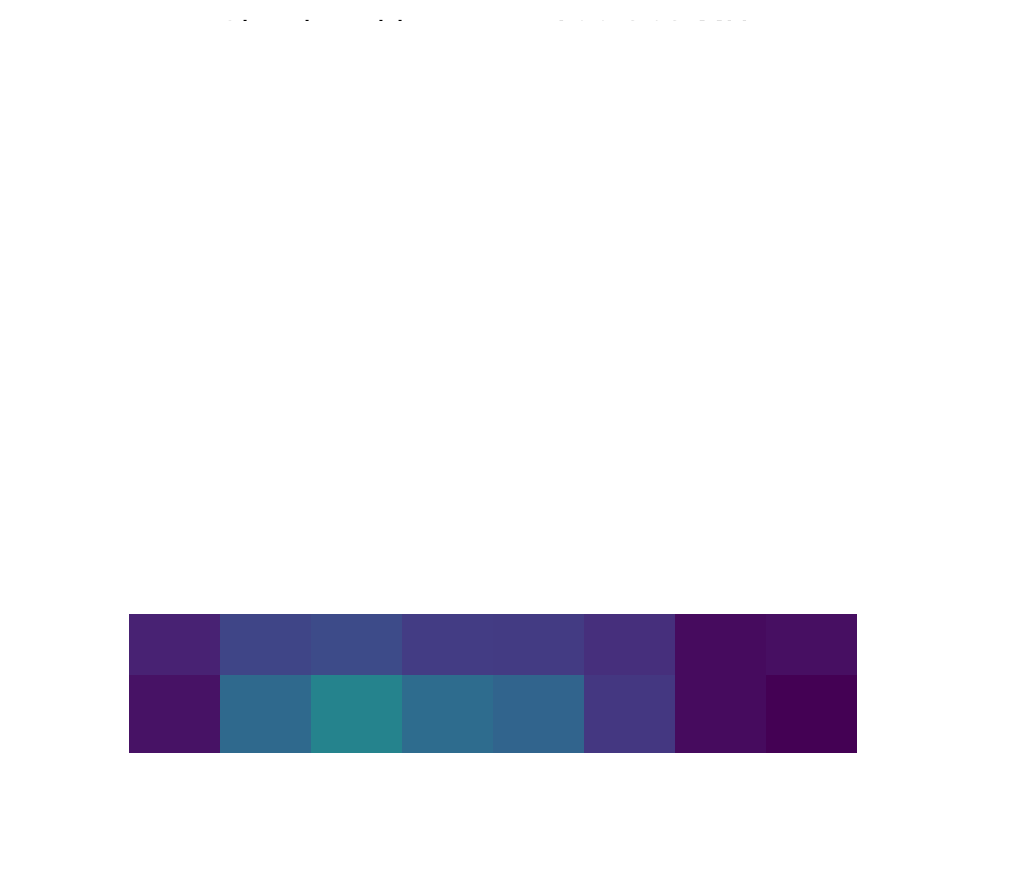

In [17]:
psf, psf_extent = make_image(np.ones_like(acm), num_pix, uv, f)

# Plot image
fig, ax = plt.subplots(figsize=(5, 5))

im_psf = ax.imshow(psf, extent=psf_extent, origin='lower')

ax.set_title(f"Simulated image at {f.to(u.MHz):.3f}")
ax.set_xlabel("pixel x")
ax.set_ylabel("pixel y")

cbar = fig.colorbar(im_psf, ax=ax, fraction=0.046, pad=0.04)
plt.show()


### Perform clean algorithm on simulated data

### Simulate time delays

In [19]:
def add_delay_errors(acm, frequency, delay_rms_ns, seed=None):
    freq = frequency.to(u.Hz)
    
    n_ant = acm.shape[0]

    # Independent delay error for each antenna (seconds)
    delays = np.random.normal(0, delay_rms_ns *1e-9, n_ant)

    # Delay difference for each antenna pair
    delay_matrix = delays[None, :] - delays[:, None]

    # Convert delay errors to phase errors
    phase_errors = 2 * np.pi * freq * delay_matrix

    # Apply phase errors to the visibility matrix
    acm_corrupted = acm * np.exp(1j * phase_errors.value)

    return acm_corrupted, delays

Output()

Output()

Output()

Output()

Output()

Output()

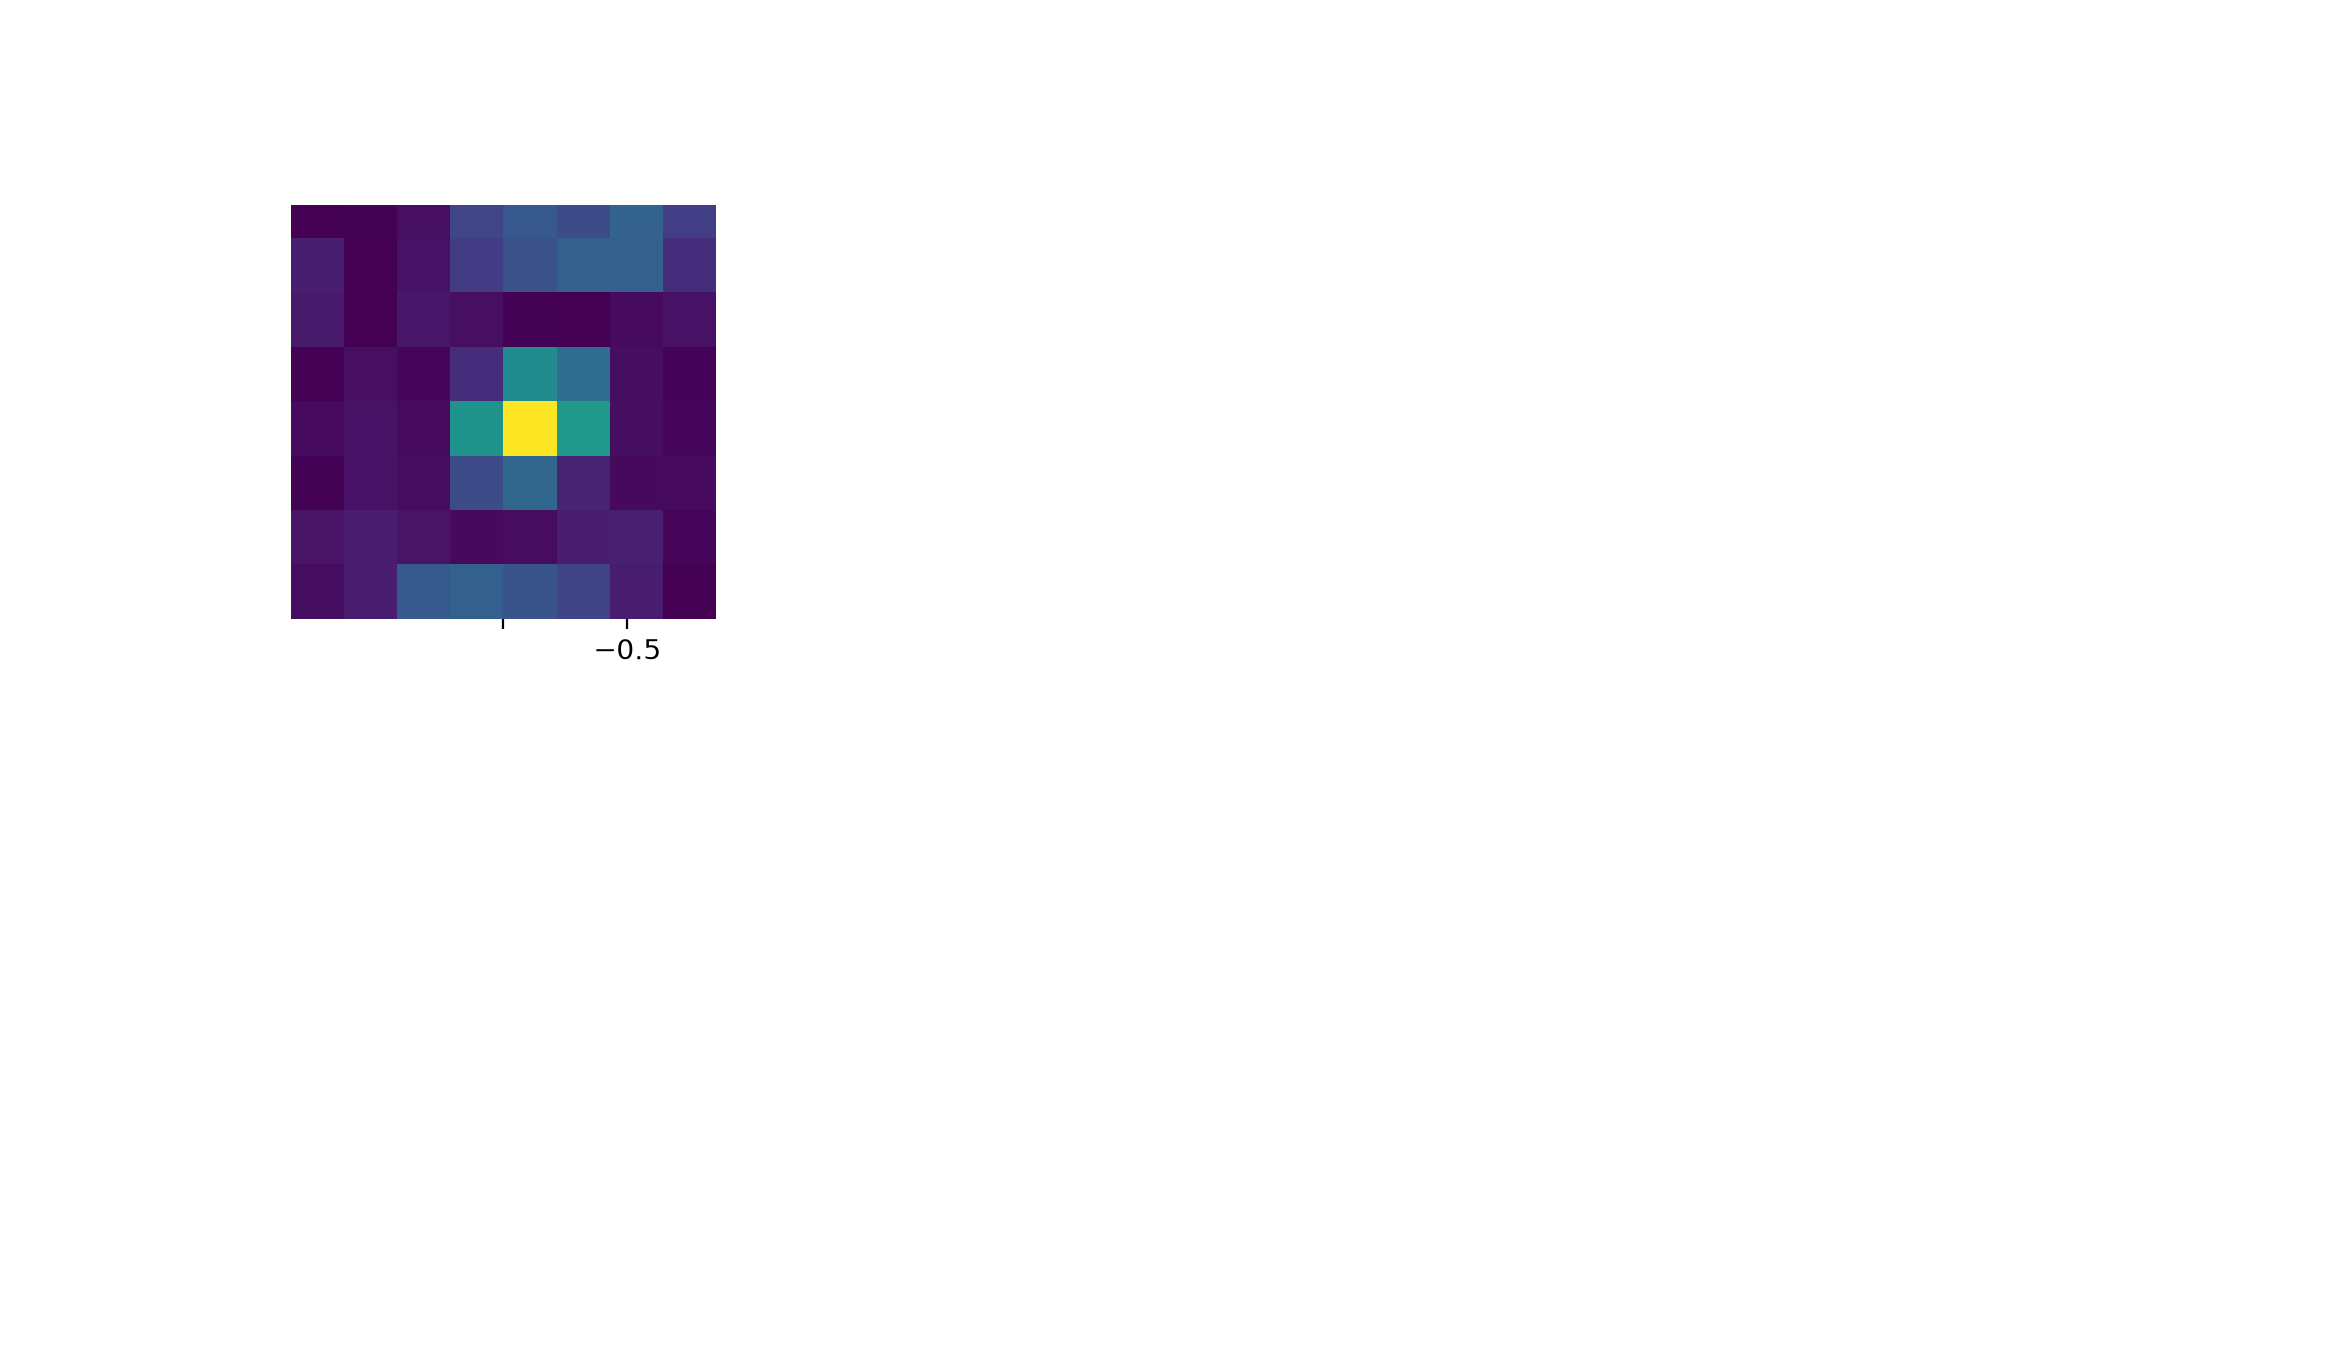

In [22]:
delay_errors = [0, 0.1, 0.5, 1, 2, 5]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for ax, delay_ns in zip(axes.flat, delay_errors):

    acm_test, delays = add_delay_errors(acm, f, delay_ns)

    img, extent = make_image(acm_test, num_pix, uv, f)

    im = ax.imshow(img, origin="lower", extent=extent)

    ax.set_title(f"Delay RMS = {delay_ns} ns")
    ax.set_xlabel("l [rad]")
    ax.set_ylabel("m [rad]")

    fig.colorbar(im, ax=ax)

plt.show()
